### Problem 1: Exploring FT of varying waveforms
Given the waveforms from the pool below, produce a $1 \times 3$ plot containing the following:
1. the signal, with its variations,
2. the magnitude of its Fourier transform, and
3. the phase information of the transform (up to you if unwrapped or not).

Below the plot, add 2-3 sentences explaining how changing the shape of the input signal affects its transform. Ex: for the Gaussian waveform, how does its Fourier transform change based on increasing or decreasing sigma?

Waveforms (preferably non-sinusoidal):
* Square wave (both single and periodic)
* Triangle wave (sawtooth, ramp, reverse ramp)
* Gaussian function (vary sigma)
* Finite-tie sinusoid
* Gaussian wave packet

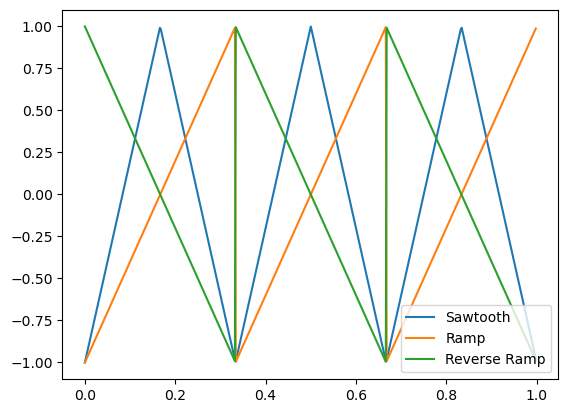

In [24]:
from scipy import signal

N_triangle = 500
t_triangle = np.linspace(0, 1, N_triangle, endpoint = False)
signal_freq = 3
triangle_dt = t_triangle[1] - t_triangle[0]

sawtooth = signal.sawtooth(2 * np.pi * signal_freq * t_triangle, width = 0.5)
ramp = signal.sawtooth(2 * np.pi * signal_freq * t_triangle, width = 1)
reverse_ramp = signal.sawtooth(2 * np.pi * signal_freq * t_triangle, width = 0)



plt.figure()
plt.plot(t_triangle, sawtooth, label = "Sawtooth")
plt.plot(t_triangle, ramp, label = "Ramp")
plt.plot(t_triangle, reverse_ramp, label = "Reverse Ramp")
plt.legend()
plt.show()

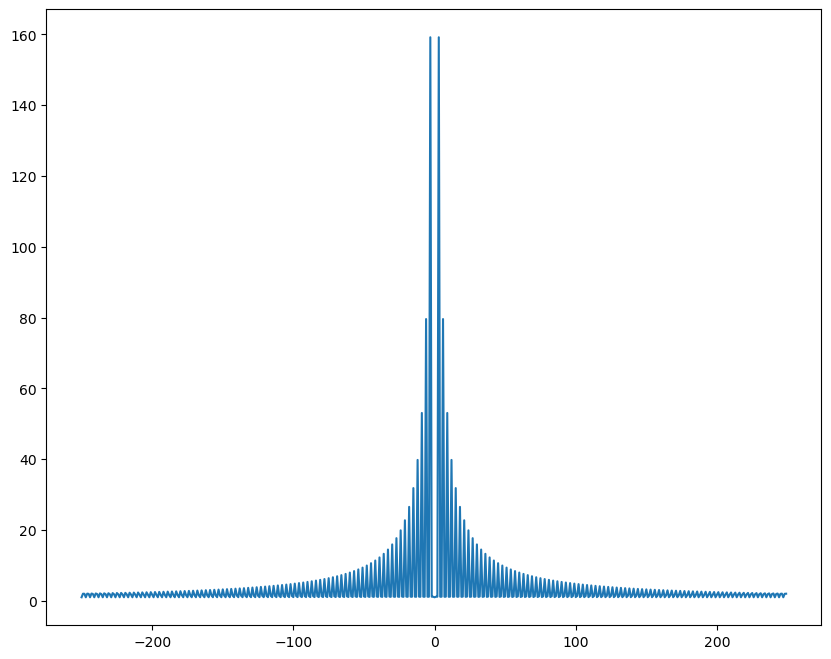

In [20]:
four_square = np.abs(np.fft.fftshift(np.fft.fft(square)))
four_square_dt = np.fft.fftshift(np.fft.fftfreq(N_square, square_dt))

plt.figure(figsize=(10,8))
plt.plot(four_square_dt, four_square)

### Problem 3
1. Create a signal of a frequency using different sampling frequencies (uniform sampling)
2. Get their fourier transform
3. Plot: Show the fourier transform of an aliased signal, how it looks like in the time domain, and how the actual signal looks like in the time domain if its not aliased

Discussion: Explain the report figure

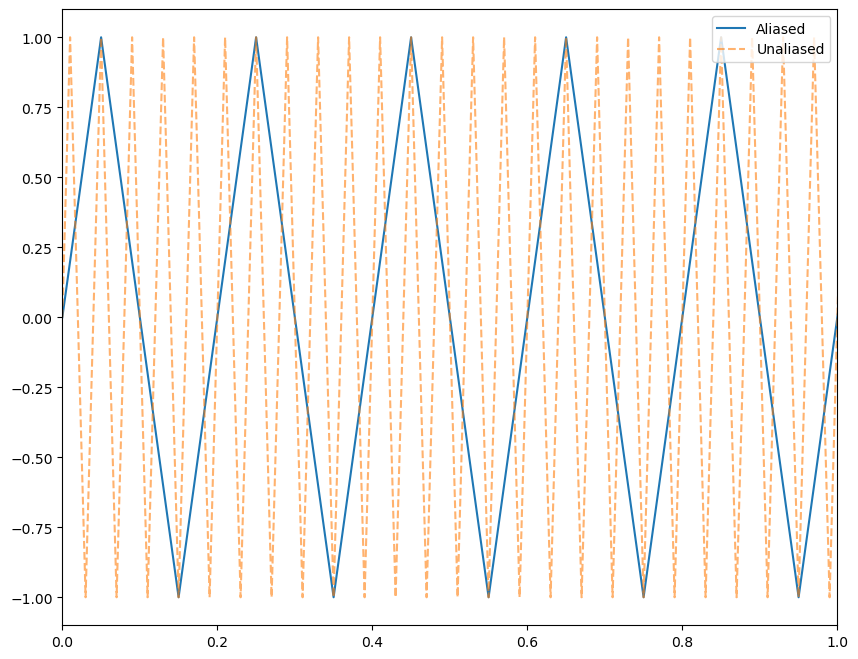

In [21]:
import numpy as np
import matplotlib.pyplot as plt

N_aliased = 200
N_unaliased = 1000
t = 10
dt = t / N_aliased
dt_un = t / N_unaliased
t_aliased = np.arange(N_aliased) * dt
t_unaliased = np.arange(N_unaliased) * dt_un

freq = 25 # Way past the limit of our aliased signal which samples at 20 per second while its highest presentable frequency is only 10)

def cont_signal(freq, time):
    return np.sin(2 * np.pi * freq * time) # + np.sin(2 * np.pi * 3.5 * time)

discrete_aliased = cont_signal(freq, t_aliased)
discrete_unaliased = cont_signal(freq, t_unaliased)

plt.figure(figsize=(10,8))
plt.plot(t_aliased, discrete_aliased, label = "Aliased")
plt.plot(t_unaliased, discrete_unaliased, linestyle="--", alpha = 0.6, label = "Unaliased")
plt.xlim(0,1)
plt.legend()
plt.show()

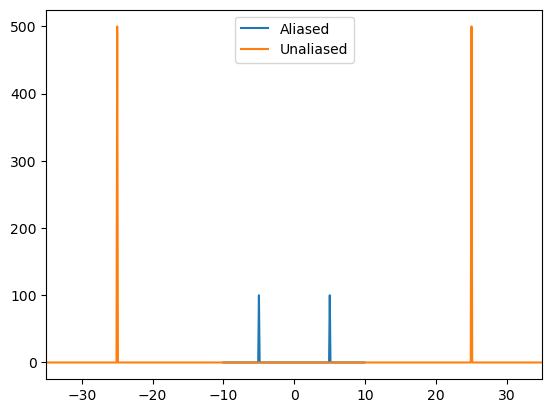

In [22]:
four_sample = np.abs(np.fft.fftshift(np.fft.fft(discrete_signal)))
four_dt = np.fft.fftshift(np.fft.fftfreq(N_aliased, dt))
four_disun = np.abs(np.fft.fftshift(np.fft.fft(discrete_unaliased)))
four_un = np.fft.fftshift(np.fft.fftfreq(N_unaliased, dt_un))

plt.figure()
plt.plot(four_dt, four_sample, label = "Aliased")
plt.plot(four_un, four_disun, label = "Unaliased")
plt.xlim(-35,35)
plt.legend()
plt.show()